<a href="https://colab.research.google.com/github/Mufliha-Hafsyah/Machine-Learning/blob/main/UTS_Klastering/Kmeans_Perbandingan_K.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **KUIS & UTS MATA KULIAH PEMBELAJARAN MESIN**

**Nama**  : Mufliha Hafsyah Shahieza <br>
**NIM**   : 244107020147 <br>
**Kelas** : TI-3G

---

# **PERBANDINGAN 3 METODE K-MEANS DENGAN K YANG SAMA**


In [ ]:
# Import library & setting
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, Normalizer
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, pairwise_distances)
from google.colab import drive
drive.mount('/content/drive')

warnings.filterwarnings('ignore')
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

OUTPUT_DIR = "/content/drive/MyDrive/UTSML2026/outputKmeans"
os.makedirs(OUTPUT_DIR, exist_ok=True)

Mounted at /content/drive


In [ ]:
# Load Dataset
df_raw = pd.read_csv('/content/drive/MyDrive/UTSML2026/dataset/diabetes_binary_5050split_health_indicators_BRFSS2015.csv')
print(f"Data awal: {df_raw.shape[0]} baris x {df_raw.shape[1]} kolom")
df_raw.head()


Data awal: 70692 baris x 22 kolom


,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,0.0,1.0,26.0,0.0,0.0,0.0,1.0,0.0,...,1.0,0.0,3.0,5.0,30.0,0.0,1.0,4.0,6.0,8.0
1,0.0,1.0,1.0,1.0,26.0,1.0,1.0,0.0,0.0,1.0,...,1.0,0.0,3.0,0.0,0.0,0.0,1.0,12.0,6.0,8.0
2,0.0,0.0,0.0,1.0,26.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,1.0,0.0,10.0,0.0,1.0,13.0,6.0,8.0
3,0.0,1.0,1.0,1.0,28.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,3.0,0.0,3.0,0.0,1.0,11.0,6.0,8.0
4,0.0,0.0,0.0,1.0,29.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,8.0,5.0,8.0


In [ ]:
# Preprocessing
df = df_raw.copy()
n_awal = len(df)
print(f"Data awal                  : {df.shape[0]} baris, {df.shape[1]} kolom")

# Catatan: Dataset 'diabetes_binary_5050split' hanya memiliki kelas 0.0 (non-diabetes) dan 1.0 (diabetes).
# Kelas 1 tidak dibuang karena merupakan kelas target diabetes yang dibutuhkan.

# Membuang 6 kolom agar tersisa 15 fitur (sama dengan notebook per metode)
FITUR_DIBUANG = ['Income', 'CholCheck', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'Education']
df = df.drop(columns=FITUR_DIBUANG)               # <-- baris yang sebelumnya terlewat
print(f"Setelah buang 6 kolom      : {df.shape[1]} kolom")

# Menghapus baris duplikat
n_sebelum_dup = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Setelah hapus duplikat     : {len(df)} baris (terbuang {n_sebelum_dup - len(df)})")
print(df['Diabetes_binary'].value_counts().sort_index())

# Pisahkan tabel fitur dan label
y_label = df['Diabetes_binary'].copy()
df_features = df.drop(columns=['Diabetes_binary']).astype(float)
print(f"Jumlah fitur untuk klastering: {df_features.shape[1]}")
print(f"Daftar fitur: {list(df_features.columns)}")

# Standardisasi
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_features.values)
print(f"Bentuk data siap klaster (StandardScaler): {X_scaled.shape}")

# Normalisasi L2 (untuk K-Means Cosine)
normalizer = Normalizer(norm='l2')
X_norm = normalizer.fit_transform(X_scaled)

print(f"X_scaled: {X_scaled.shape} | X_norm: {X_norm.shape}")
print(f"Cek norma L2 tiga baris pertama X_norm (harus 1): {np.linalg.norm(X_norm[:3], axis=1)}")

Data awal                  : 70692 baris, 22 kolom
Setelah buang 6 kolom      : 16 kolom
Setelah hapus duplikat     : 63197 baris (terbuang 7495)
Diabetes_binary
0.0    29885
1.0    33312
Name: count, dtype: int64
Jumlah fitur untuk klastering: 15
Daftar fitur: ['HighBP', 'HighChol', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age']
Bentuk data siap klaster (StandardScaler): (63197, 15)
X_scaled: (63197, 15) | X_norm: (63197, 15)
Cek norma L2 tiga baris pertama X_norm (harus 1): [1. 1. 1.]


In [ ]:
class KMeansEuclidean:
    def __init__(self, n_clusters=3, max_iter=300, tol=1e-4, random_state=42):
        self.n_clusters = n_clusters
        self.max_iter = max_iter
        self.tol = tol
        self.random_state = random_state
        self.centroids = None
        self.labels_ = None
        self.inertia_ = 0.0
        self.n_iter_ = 0
        self.execution_time_ = 0.0

    def _compute_distance(self, X, centroids):
        # Euclidean distance matrix: ||X - centroids||_2
        return pairwise_distances(X, centroids, metric='euclidean')

    def _init_centroids(self, X):
        rng = np.random.RandomState(self.random_state)
        n_samples, _ = X.shape
        first_idx = rng.randint(n_samples)
        centroids = [X[first_idx]]

        for _ in range(1, self.n_clusters):
            cur_c = np.array(centroids)
            dists = self._compute_distance(X, cur_c)
            min_dists = np.min(dists, axis=1)
            sq_dists = min_dists ** 2
            sum_sq = np.sum(sq_dists)
            probs = np.ones(n_samples) / n_samples if sum_sq == 0 else sq_dists / sum_sq
            next_idx = rng.choice(n_samples, p=probs)
            centroids.append(X[next_idx])
        return np.array(centroids)

    def fit(self, X):
        start_time = time.perf_counter()
        self.centroids = self._init_centroids(X)

        for it in range(self.max_iter):
            self.n_iter_ = it + 1
            # Assignment Step: Penugasan sampel ke centroid Euclidean terdekat
            dists = self._compute_distance(X, self.centroids)
            labels = np.argmin(dists, axis=1)

            # Update Step: Pembaruan posisi centroid menggunakan rata-rata aritmetika (mean)
            new_centroids = np.zeros_like(self.centroids)
            rng = np.random.RandomState(self.random_state)
            for k in range(self.n_clusters):
                cluster_pts = X[labels == k]
                if len(cluster_pts) == 0:
                    new_centroids[k] = X[rng.randint(len(X))]
                else:
                    new_centroids[k] = np.mean(cluster_pts, axis=0)

            # Pengecekan konvergensi pergeseran centroid
            shift = np.linalg.norm(new_centroids - self.centroids)
            self.centroids = new_centroids
            self.labels_ = labels

            if shift < self.tol:
                break

        # Komputasi Nilai Fungsi Objektif SSE: J = sum_{k=1}^K sum_{x in S_k} ||x - mu_k||_2^2
        final_dists = self._compute_distance(X, self.centroids)
        assigned_dists = final_dists[np.arange(len(X)), self.labels_]
        self.inertia_ = float(np.sum(assigned_dists ** 2))
        self.execution_time_ = float(time.perf_counter() - start_time)
        return self

print("[INFO] Kelas KMeansEuclidean berhasil diinisialisasi.")

[INFO] Kelas KMeansEuclidean berhasil diinisialisasi.


In [ ]:
# Class Kmeans
class KMeansManhattan:
    """K-Means dengan jarak Manhattan (L1). Centroid diupdate pakai median per dimensi."""
    def __init__(self, n_clusters=3, max_iter=300, tol=1e-4, random_state=42):
        self.n_clusters = n_clusters
        self.max_iter = max_iter
        self.tol = tol
        self.random_state = random_state
        self.centroids = None
        self.labels_ = None
        self.inertia_ = 0.0
        self.n_iter_ = 0
        self.execution_time_ = 0.0

    def _compute_distance(self, X, centroids):
        return pairwise_distances(X, centroids, metric='manhattan', n_jobs=-1)

    def _init_centroids(self, X):
        rng = np.random.RandomState(self.random_state)
        n_samples, _ = X.shape
        first_idx = rng.randint(n_samples)
        centroids = [X[first_idx]]

        for _ in range(1, self.n_clusters):
            cur_c = np.array(centroids)
            dists = self._compute_distance(X, cur_c)
            min_dists = np.min(dists, axis=1)
            sq_dists = min_dists ** 2
            sum_sq = np.sum(sq_dists)
            probs = np.ones(n_samples) / n_samples if sum_sq == 0 else sq_dists / sum_sq
            next_idx = rng.choice(n_samples, p=probs)
            centroids.append(X[next_idx])
        return np.array(centroids)

    def fit(self, X):
        start_time = time.perf_counter()
        self.centroids = self._init_centroids(X)

        for it in range(self.max_iter):
            self.n_iter_ = it + 1
            dists = self._compute_distance(X, self.centroids)
            labels = np.argmin(dists, axis=1)

            new_centroids = np.zeros_like(self.centroids)
            rng = np.random.RandomState(self.random_state)
            for k in range(self.n_clusters):
                cluster_pts = X[labels == k]
                if len(cluster_pts) == 0:
                    new_centroids[k] = X[rng.randint(len(X))]
                else:
                    new_centroids[k] = np.median(cluster_pts, axis=0)
            shift = np.linalg.norm(new_centroids - self.centroids)
            self.centroids = new_centroids
            self.labels_ = labels

            if shift < self.tol:
                break

        final_dists = self._compute_distance(X, self.centroids)
        assigned_dists = final_dists[np.arange(len(X)), self.labels_]
        self.inertia_ = float(np.sum(assigned_dists))
        self.execution_time_ = float(time.perf_counter() - start_time)
        return self

print("[INFO] Kelas KMeansManhattan berhasil diinisialisasi.")

[INFO] Kelas KMeansManhattan berhasil diinisialisasi.


In [ ]:
# Model Kmeans
class KMeansCosine:
    """K-Means dengan jarak Cosine. Centroid = rata-rata vektor yang dinormalisasi lagi ke bola satuan."""
    def __init__(self, n_clusters=3, max_iter=300, tol=1e-4, random_state=42):
        self.n_clusters = n_clusters
        self.max_iter = max_iter
        self.tol = tol
        self.random_state = random_state
        self.centroids = None
        self.labels_ = None
        self.inertia_ = 0.0
        self.n_iter_ = 0
        self.execution_time_ = 0.0

    def _compute_distance(self, X, centroids):
        return pairwise_distances(X, centroids, metric='cosine', n_jobs=-1)

    def _init_centroids(self, X):
        rng = np.random.RandomState(self.random_state)
        n_samples, _ = X.shape
        first_idx = rng.randint(n_samples)
        centroids = [X[first_idx]]

        for _ in range(1, self.n_clusters):
            cur_c = np.array(centroids)
            dists = self._compute_distance(X, cur_c)
            min_dists = np.min(dists, axis=1)
            sq_dists = min_dists ** 2
            sum_sq = np.sum(sq_dists)
            probs = np.ones(n_samples) / n_samples if sum_sq == 0 else sq_dists / sum_sq
            next_idx = rng.choice(n_samples, p=probs)
            centroids.append(X[next_idx])

        centroids = np.array(centroids)
        norms = np.linalg.norm(centroids, axis=1, keepdims=True)
        norms[norms == 0] = 1e-10
        return centroids / norms

    def fit(self, X):
        start_time = time.perf_counter()

        norms = np.linalg.norm(X, axis=1, keepdims=True)
        norms[norms == 0] = 1e-10
        X_calc = X / norms

        self.centroids = self._init_centroids(X_calc)

        for it in range(self.max_iter):
            self.n_iter_ = it + 1
            dists = self._compute_distance(X_calc, self.centroids)
            labels = np.argmin(dists, axis=1)

            new_centroids = np.zeros_like(self.centroids)
            rng = np.random.RandomState(self.random_state)
            for k in range(self.n_clusters):
                cluster_pts = X_calc[labels == k]
                if len(cluster_pts) == 0:
                    new_centroids[k] = X_calc[rng.randint(len(X_calc))]
                else:
                    mean_vec = np.mean(cluster_pts, axis=0)
                    norm = np.linalg.norm(mean_vec)
                    new_centroids[k] = mean_vec / (norm if norm > 0 else 1.0)

            shift = np.linalg.norm(new_centroids - self.centroids)
            self.centroids = new_centroids
            self.labels_ = labels

            if shift < self.tol:
                break

        final_dists = self._compute_distance(X_calc, self.centroids)
        assigned_dists = final_dists[np.arange(len(X_calc)), self.labels_]
        self.inertia_ = float(np.sum(assigned_dists))
        self.execution_time_ = float(time.perf_counter() - start_time)
        return self

print("[INFO] Kelas KMeansCosine berhasil diinisialisasi.")

[INFO] Kelas KMeansCosine berhasil diinisialisasi.


In [ ]:
# Jalankan 3 metrik jarak pada K yang SAMA (K = 2..6)
K_LIST = [2, 3, 4, 5, 6]

konfigurasi = [
    ('Euclidean', KMeansEuclidean, X_scaled, 'euclidean'),
    ('Manhattan', KMeansManhattan, X_scaled, 'manhattan'),
    ('Cosine',    KMeansCosine,    X_norm,   'cosine'),
]

hasil = []
for k in K_LIST:
    for nama, Model, X, metrik_sil in konfigurasi:
        model = Model(n_clusters=k, max_iter=300, tol=1e-4, random_state=RANDOM_STATE)
        model.fit(X)
        lab = model.labels_

        sil = silhouette_score(X, lab, metric=metrik_sil,
                               sample_size=10000, random_state=RANDOM_STATE)
        db  = davies_bouldin_score(X, lab)
        ch  = calinski_harabasz_score(X, lab)

        hasil.append({
            'K': k,
            'Metrik Jarak': nama,
            'Silhouette (↑)': round(sil, 4),
            'Davies-Bouldin (↓)': round(db, 4),
            'Calinski-Harabasz (↑)': round(ch, 2),
            'Waktu (s) (↓)': round(model.execution_time_, 3),
            'Iterasi (↓)': model.n_iter_,
        })
        print(f"K={k} | {nama:9s} | Sil={sil:.4f} | DB={db:.4f} | CH={ch:,.0f} | iter={model.n_iter_}")

df_k = pd.DataFrame(hasil)
df_k

K=2 | Euclidean | Sil=0.1756 | DB=2.3744 | CH=10,209 | iter=24
K=2 | Manhattan | Sil=0.2037 | DB=2.8072 | CH=7,010 | iter=7
K=2 | Cosine    | Sil=0.2232 | DB=2.5666 | CH=9,397 | iter=18
K=3 | Euclidean | Sil=0.1712 | DB=2.2111 | CH=7,727 | iter=22
K=3 | Manhattan | Sil=0.1586 | DB=3.0513 | CH=5,671 | iter=9
K=3 | Cosine    | Sil=0.1931 | DB=2.6392 | CH=7,271 | iter=18
K=4 | Euclidean | Sil=0.1068 | DB=2.3585 | CH=7,218 | iter=23
K=4 | Manhattan | Sil=0.1259 | DB=2.9280 | CH=5,125 | iter=5
K=4 | Cosine    | Sil=0.1982 | DB=2.5052 | CH=6,258 | iter=23
K=5 | Euclidean | Sil=0.1073 | DB=2.2535 | CH=6,491 | iter=54
K=5 | Manhattan | Sil=0.1203 | DB=2.7317 | CH=4,614 | iter=5
K=5 | Cosine    | Sil=0.1985 | DB=2.4634 | CH=5,712 | iter=27
K=6 | Euclidean | Sil=0.1038 | DB=2.2721 | CH=5,933 | iter=34
K=6 | Manhattan | Sil=0.1246 | DB=2.6280 | CH=4,334 | iter=6
K=6 | Cosine    | Sil=0.2107 | DB=2.3694 | CH=5,396 | iter=50


,K,Metrik Jarak,Silhouette (↑),Davies-Bouldin (↓),Calinski-Harabasz (↑),Waktu (s) (↓),Iterasi (↓)
0,2,Euclidean,0.1756,2.3744,10209.26,0.511,24
1,2,Manhattan,0.2037,2.8072,7009.74,0.367,7
2,2,Cosine,0.2232,2.5666,9397.32,0.766,18
3,3,Euclidean,0.1712,2.2111,7727.05,0.467,22
4,3,Manhattan,0.1586,3.0513,5670.96,0.721,9
5,3,Cosine,0.1931,2.6392,7270.62,1.839,18
6,4,Euclidean,0.1068,2.3585,7218.13,0.608,23
7,4,Manhattan,0.1259,2.9280,5124.80,0.268,5
8,4,Cosine,0.1982,2.5052,6258.32,1.083,23
9,5,Euclidean,0.1073,2.2535,6491.37,2.206,54


In [ ]:
# Tabel per K + pemenang tiap metrik
for k in K_LIST:
    sub = df_k[df_k['K'] == k].reset_index(drop=True)
    print("=" * 90)
    print(f"K = {k}")
    print("=" * 90)
    print(sub.drop(columns='K').to_string(index=False))
    print(f"  Silhouette tertinggi      : {sub.loc[sub['Silhouette (↑)'].idxmax(), 'Metrik Jarak']}")
    print(f"  Davies-Bouldin terendah   : {sub.loc[sub['Davies-Bouldin (↓)'].idxmin(), 'Metrik Jarak']}")
    print(f"  Calinski-Harabasz tertinggi: {sub.loc[sub['Calinski-Harabasz (↑)'].idxmax(), 'Metrik Jarak']}")
    print(f"  Tercepat                  : {sub.loc[sub['Waktu (s) (↓)'].idxmin(), 'Metrik Jarak']}\n")

# Rekap: berapa kali tiap metrik jarak menang (3 metrik kualitas x 5 nilai K = 15 pertandingan)
menang = {'Euclidean': 0, 'Manhattan': 0, 'Cosine': 0}
for k in K_LIST:
    sub = df_k[df_k['K'] == k]
    menang[sub.loc[sub['Silhouette (↑)'].idxmax(), 'Metrik Jarak']] += 1
    menang[sub.loc[sub['Davies-Bouldin (↓)'].idxmin(), 'Metrik Jarak']] += 1
    menang[sub.loc[sub['Calinski-Harabasz (↑)'].idxmax(), 'Metrik Jarak']] += 1
print("Rekap kemenangan (dari 15):", menang)

K = 2
Metrik Jarak  Silhouette (↑)  Davies-Bouldin (↓)  Calinski-Harabasz (↑)  Waktu (s) (↓)  Iterasi (↓)
   Euclidean          0.1756              2.3744               10209.26          0.511           24
   Manhattan          0.2037              2.8072                7009.74          0.367            7
      Cosine          0.2232              2.5666                9397.32          0.766           18
  Silhouette tertinggi      : Cosine
  Davies-Bouldin terendah   : Euclidean
  Calinski-Harabasz tertinggi: Euclidean
  Tercepat                  : Manhattan

K = 3
Metrik Jarak  Silhouette (↑)  Davies-Bouldin (↓)  Calinski-Harabasz (↑)  Waktu (s) (↓)  Iterasi (↓)
   Euclidean          0.1712              2.2111                7727.05          0.467           22
   Manhattan          0.1586              3.0513                5670.96          0.721            9
      Cosine          0.1931              2.6392                7270.62          1.839           18
  Silhouette tertinggi      :

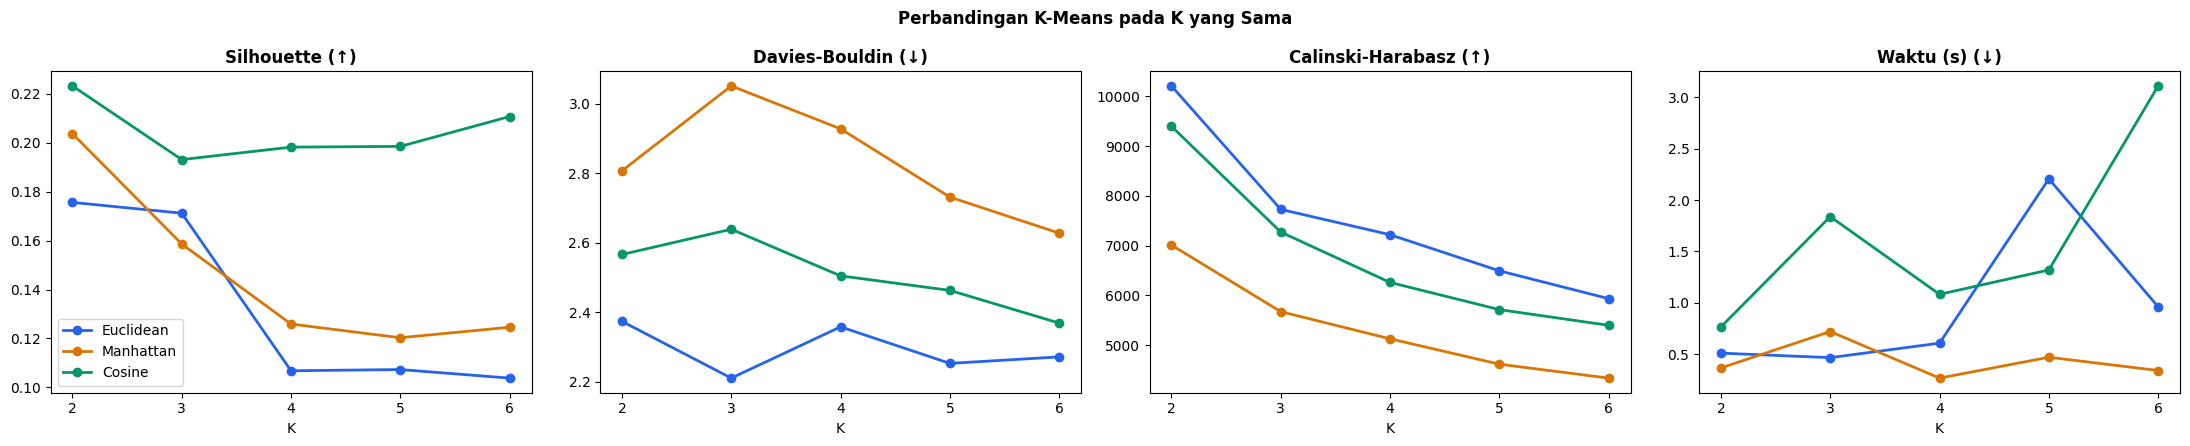

[SIMPAN] Hasil perbandingan K tersimpan.


In [ ]:
# Grafik perbandingan lintas K + simpan hasil
warna = {'Euclidean': '#2563EB', 'Manhattan': '#D97706', 'Cosine': '#059669'}
panel = ['Silhouette (↑)', 'Davies-Bouldin (↓)', 'Calinski-Harabasz (↑)', 'Waktu (s) (↓)']

fig, axes = plt.subplots(1, 4, figsize=(22, 4.5))
for ax, m in zip(axes, panel):
    for nama, c in warna.items():
        s = df_k[df_k['Metrik Jarak'] == nama]
        ax.plot(s['K'], s[m], marker='o', linewidth=2, color=c, label=nama)
    ax.set_title(m, fontweight='bold')
    ax.set_xlabel('K')
    ax.set_xticks(K_LIST)
axes[0].legend()
plt.suptitle('Perbandingan K-Means pada K yang Sama', fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'perbandingan_k_sama.png'), dpi=300)
plt.show()

df_k.to_excel(os.path.join(OUTPUT_DIR, 'perbandingan_kmeans_k_sama.xlsx'), index=False)
print("[SIMPAN] Hasil perbandingan K tersimpan.")